# Investigation of Data Processing and Filtering for PCA

The user asked:
> I want to explore how is the data cleaning, filtering, and processing are conducted before PCA analysis. Does the current PCA analysis in the pipeline output the details of the process? for example how many stations are dropped with .dropna(). And then the total time period used for the correlation analysis of each parameter, basin, depth layer, and seasons permutation.

## Summary of Findings
1. **Pre-PCA Processing (`step4_PCA_analysis/process11...`)**: The PCA analysis itself **does not use `.dropna()`** on stations. Instead, it takes the `yearly_do_df` (which contains NaN values where DO was not sampled) and applies a **spatial interpolation** based on a Gaussian distance weighting and a pre-calculated decorrelation scale. Any remaining missing values are filled with the mean of the station or overall column mean. Therefore, no stations are dropped right before the PCA step; they are gap-filled. The pipeline currently does not explicitly output a report of how many NaNs were interpolated versus filled by mean for the PCA.
2. **Correlation Analysis (Step 5 and Step 6)**: Both `step5` (e.g. `process42_time_series_...`) and `step6` (`process01_pc_driver_temporal_analysis.py`) use the same overlapping-year approach. During the correlation of PC scores against environmental factors, the script **does use `.dropna()`** on the environmental time series for each station. It calculates the correlation using only the intersecting years where both PC score and environmental data are valid. It requires a minimum of 5 years of overlapping data. The output `.csv` files from this step save a column `[parameter]_n` which specifies exactly how many years of data were used for that specific correlation.

Below, we will explore both of these mechanisms with code and visualizations.


In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import sys

# Setup paths
PROJECT_ROOT = Path("/home/reyha/SIS_Analysis_WSL")
sys.path.append(str(PROJECT_ROOT))
from utils.paths import ProjectPaths

plt.style.use(str(PROJECT_ROOT / 'project_style.mplstyle'))


## 1. Data Availability Before PCA
Let's load the `yearly_do_df` for Summer Bottom layer, which is the input to the PCA analysis.
We can visualize how much missing data exists before the interpolation step.


Total shape of yearly_do_df: (185, 43) (Stations x Years)
Total missing values: 502 out of 7955 (6.31%)


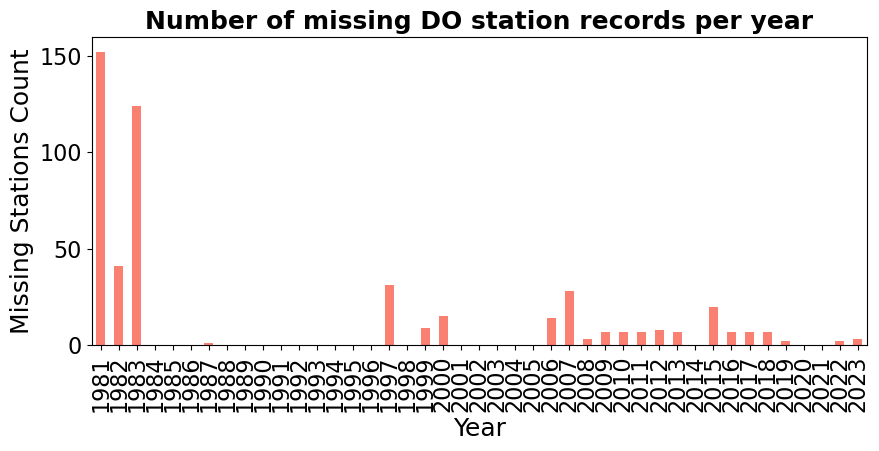

In [10]:
# Load pre-filtered DO data
season = 'Summer'
layer = 'bottom'
yearly_do_file = ProjectPaths.get_subset_dir(season, layer) / "yearly_do_df.csv"

if yearly_do_file.exists():
    yearly_do_df = pd.read_csv(yearly_do_file, index_col=0)
    yearly_do_df.index = yearly_do_df.index.astype(str).str.zfill(8)
    
    # Calculate missing data percentage
    total_cells = yearly_do_df.size
    missing_cells = yearly_do_df.isna().sum().sum()
    print(f"Total shape of yearly_do_df: {yearly_do_df.shape} (Stations x Years)")
    print(f"Total missing values: {missing_cells} out of {total_cells} ({missing_cells/total_cells*100:.2f}%)")
    
    # Plot missing data distribution per year
    plt.figure(figsize=(10, 4))
    missing_per_year = yearly_do_df.isna().sum()
    missing_per_year.plot(kind='bar', color='salmon')
    plt.title('Number of missing DO station records per year')
    plt.ylabel('Missing Stations Count')
    plt.xlabel('Year')
    plt.show()
else:
    print(f"File not found: {yearly_do_file}")


## 2. Gap-filling instead of Dropna
The PCA script uses `interpolate_missing_do` and then `fillna` instead of dropping stations.


In [11]:
# Example of how missing data is filled in the PCA script
def simulate_pca_filling(df):
    # The actual script does spatial interpolation first.
    # For simplicity, we just show the fallback mean-filling part.
    mean_fallback = df.mean(axis=1)
    df_filled = df.copy()
    for col in df_filled.columns:
        df_filled[col] = df_filled[col].fillna(mean_fallback)
    
    # Any remaining NaNs (e.g. stations with no data at all) are filled with column means
    df_filled = df_filled.fillna(df_filled.mean(axis=0))
    return df_filled

if 'yearly_do_df' in locals():
    # Let's filter for just Tokyo Bay as an example
    merged_gdf = pd.read_feather(ProjectPaths.MERGED_DATA_FILE)
    tb_stations = merged_gdf[merged_gdf['watermass_name'] == 'Tokyo Bay']['zettaicode'].unique()
    tb_stations_str = [str(st).zfill(8) for st in tb_stations]
    tb_df = yearly_do_df[yearly_do_df.index.isin(tb_stations_str)]
    
    tb_filled = simulate_pca_filling(tb_df)
    print(f"Before filling: {tb_df.isna().sum().sum()} NaNs in Tokyo Bay.")
    print(f"After filling: {tb_filled.isna().sum().sum()} NaNs in Tokyo Bay. (Ready for PCA)")


Before filling: 148 NaNs in Tokyo Bay.
After filling: 0 NaNs in Tokyo Bay. (Ready for PCA)


## 3. Data Usage in Correlation Analysis
In `step6`, `.dropna()` is used on the environmental parameter side when correlating with the PC score. The script tracks how many years were valid (`_n`).
Let's read one of the correlation output files and see how many years of data were actually used for the correlations.


Correlation calculated over a maximum of 11 years.


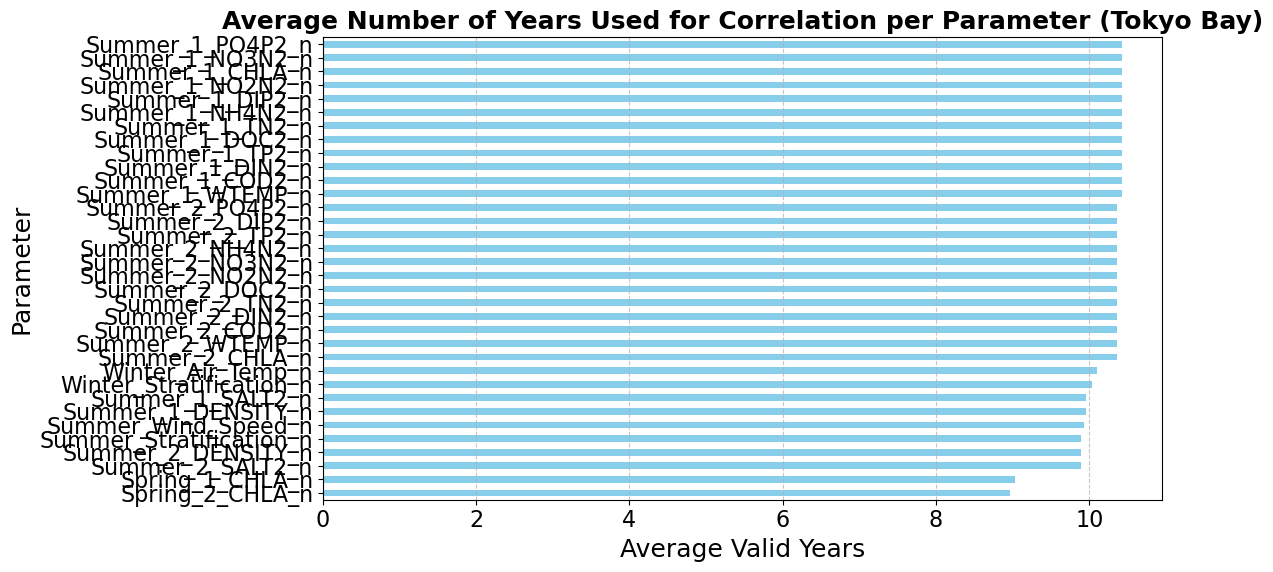

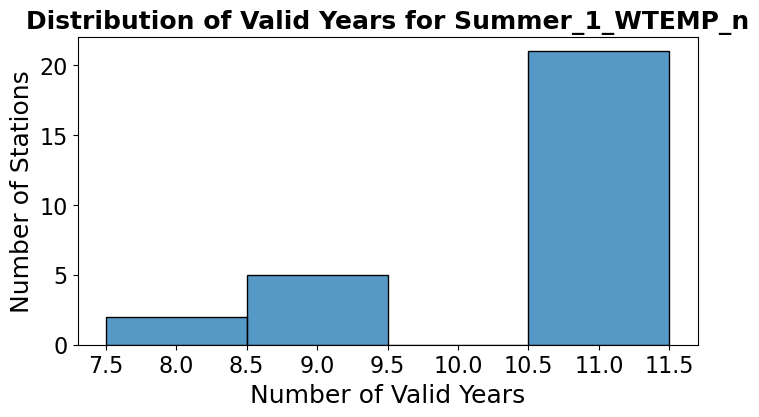

In [12]:
# Check correlation output for Tokyo Bay PC1
target_region = "tokyo_bay"
start_year = 2013
end_year = 2023
corr_dir = ProjectPaths.PROCESSED_DATA_DIR / 'step6_pick_up_area_location' / 'process01_pc_driver_temporal_analysis' / target_region / f'{start_year}-{end_year}'
corr_file = corr_dir / f'{target_region}_PC1_{start_year}_{end_year}_correlations.csv'

if corr_file.exists():
    corr_df = pd.read_csv(corr_file, index_col=0)
    
    # Extract the 'n' columns which represent the number of years used for each parameter
    n_cols = [c for c in corr_df.columns if c.endswith('_n')]
    n_df = corr_df[n_cols]
    
    print(f"Correlation calculated over a maximum of {end_year - start_year + 1} years.")
    
    # Plot the average number of years used for each parameter across all stations
    plt.figure(figsize=(12, 6))
    n_df.mean().sort_values().plot(kind='barh', color='skyblue')
    plt.title('Average Number of Years Used for Correlation per Parameter (Tokyo Bay)')
    plt.xlabel('Average Valid Years')
    plt.ylabel('Parameter')
    plt.grid(axis='x', linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.show()
    
    # Show distribution of years used for a specific parameter
    param_to_show = 'Summer_1_WTEMP_n'
    if param_to_show in n_df.columns:
        plt.figure(figsize=(8, 4))
        sns.histplot(n_df[param_to_show], bins=range(0, (end_year - start_year + 1) + 2), discrete=True)
        plt.title(f'Distribution of Valid Years for {param_to_show}')
        plt.xlabel('Number of Valid Years')
        plt.ylabel('Number of Stations')
        plt.show()
else:
    print(f"Correlation file not found: {corr_file}")
    print("You might need to run the step6 script for Tokyo Bay to generate this file first.")


## 4. Does this apply to Step 5?
Yes. The correlation analysis logic used in Step 6's orchestration is effectively identical to the logic found in Step 5's scripts, such as `step5_environmental_factor_correlation_analysis/process42_time_series_significant_stations_PC_correlation.py`.

In Step 5's `process42` script, the correlation is computed over the intersection of non-NaN indices:
```python
# From step5_environmental_factor_correlation_analysis/process42_time_series_significant_stations_PC_correlation.py (around line 113)
s_pc = pca_scores['PC1']
s_env = chla_mat[stn]
common = s_pc.index.intersection(s_env.index)
valid = s_pc.loc[common].notna() & s_env.loc[common].notna()
if valid.sum() >= 5:
    r, _ = pearsonr(s_pc.loc[common][valid], s_env.loc[common][valid])
```
Just like in Step 6, the analysis applies `.notna()` (which acts precisely as `.dropna()` by masking invalid years) on the environmental data. The number of valid intersecting years is checked (`valid.sum() >= 5`). Therefore, the exact same rules about missing data for environmental parameters apply across the entire pipeline.


## 5. Handling Completely Missing Parameters (e.g. DOC)
Unlike the primary DO dataset (which undergoes spatial interpolation before PCA to ensure a complete matrix), the **environmental drivers** (e.g. DOC, TN, TP, Chl-a) are **NOT spatially interpolated** or gap-filled.

When a parameter like Summer Bottom DOC is completely missing or very sparse for a specific basin (like Tokyo Bay):
1. The script extracts whatever raw data exists in `merged_df`.
2. It attempts to find overlapping years between the environmental parameter and the PCA scores.
3. If the number of valid overlapping years is strictly less than 5 (`valid.sum() < 5`), the correlation script yields `NaN` for both the Pearson `r` value and the `p-value`, and sets the number of years `_n` to that low count.
4. Downstream visualization scripts (like spatial maps or boxplots) automatically ignore stations that have `NaN` correlation values.

Let's verify how much data actually exists for Summer Bottom DOC in Tokyo Bay directly from `merged_df`.


In [13]:
# Investigate Tokyo Bay Summer Bottom DOC
target_region = 'Tokyo Bay'
season_filter = 'Summer'
layer_filter = 2 # 2 = bottom

print(f"Checking data availability for DOC in {target_region} ({season_filter} Bottom)...")

if 'merged_gdf' not in locals():
    merged_gdf = pd.read_feather(ProjectPaths.MERGED_DATA_FILE)

# Filter for region, season, and layer
mask = (merged_gdf['watermass_name'] == target_region) & \
       (merged_gdf['season'] == season_filter) & \
       (merged_gdf['saisuipoin'] == layer_filter)

tb_doc_data = merged_gdf.loc[mask, ['surveyyear', 'zettaicode', 'doc2']].copy()
tb_doc_data['doc2'] = pd.to_numeric(tb_doc_data['doc2'], errors='coerce')

# Drop completely missing rows for DOC
valid_doc = tb_doc_data.dropna(subset=['doc2'])

print(f"Total historical bottom summer records in Tokyo Bay: {len(tb_doc_data)}")
print(f"Total valid bottom summer DOC records in Tokyo Bay: {len(valid_doc)}")

if len(valid_doc) == 0:
    print("\nResult: Tokyo Bay has NO valid records for Summer Bottom DOC in the merged dataset.")
    print("Therefore, when correlating PC scores against Summer_2_DOC, all stations in Tokyo Bay will return NaN correlations.")
else:
    # See how many years each station has
    station_counts = valid_doc.groupby('zettaicode')['surveyyear'].nunique()
    print("\nStations with valid DOC data and their valid year count:")
    print(station_counts[station_counts > 0])
    
    # See which ones have >= 5 years (the minimum required for correlation)
    valid_for_corr = station_counts[station_counts >= 5]
    print(f"\nNumber of stations with >= 5 years of DOC data (eligible for correlation): {len(valid_for_corr)}")


Checking data availability for DOC in Tokyo Bay (Summer Bottom)...
Total historical bottom summer records in Tokyo Bay: 1207
Total valid bottom summer DOC records in Tokyo Bay: 1207

Stations with valid DOC data and their valid year count:
zettaicode
00000122    42
00000124    42
00000125    42
00000128    42
00000129    42
00001210    41
00001212    42
00001214    42
00001215    42
00001222    42
00001230    42
00001235    42
00001238    42
00001251    42
00001311    42
00001313    42
00001318    42
00001320    42
00001323    40
00001326    41
00001352    42
00001427    34
00001431    35
00001432    35
00001434    35
00001439    36
00001441    36
00001446    36
Name: surveyyear, dtype: int64

Number of stations with >= 5 years of DOC data (eligible for correlation): 28
